# DSCI 552 — Midterm Exam 1, Problem 8
## Predicting Final Grades (G3) with Linear Regression

**Dataset:** `student-mat.csv` (UCI Student Performance, math course; 395 students, `;`-separated).

> Note: the problem title mentions housing prices, but the dataset and features are student-performance data. The target is the final math grade **G3** (0–20).

In [1]:
# ---- Imports ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
SEED = 552

## (a) Data Exploration and Pre-processing
### i. Import the dataset

In [2]:
# The file uses ';' as the column separator
df_raw = pd.read_csv("student-mat.csv", sep=";")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Basic structure: column types and non-null counts
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

### ii. Select features, encode `schoolsup`, combine `Dalc`/`Walc` into `alc`

In [4]:
# Select the required features plus the target G3
cols = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]
df = df_raw[cols].copy()

# Encode the binary variable: no -> 0, yes -> 1
df["schoolsup"] = df["schoolsup"].map({"no": 0, "yes": 1})

# Combine workday (Dalc) and weekend (Walc) alcohol use into their average, then drop both
df["alc"] = (df["Dalc"] + df["Walc"]) / 2
df = df.drop(columns=["Dalc", "Walc"])

# Put the target last for readability
df = df[["age", "studytime", "schoolsup", "goout", "health", "absences", "alc", "G3"]]

# First five rows of the pre-processed dataset
df.head()

,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10


In [5]:
# Data types, summary statistics, and missing values of the pre-processed data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        395 non-null    int64  
 1   studytime  395 non-null    int64  
 2   schoolsup  395 non-null    int64  
 3   goout      395 non-null    int64  
 4   health     395 non-null    int64  
 5   absences   395 non-null    int64  
 6   alc        395 non-null    float64
 7   G3         395 non-null    int64  
dtypes: float64(1), int64(7)
memory usage: 24.8 KB


In [6]:
df.describe()

,age,studytime,schoolsup,goout,health,absences,alc,G3
count,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000
mean,16.6962,2.0354,0.1291,3.1089,3.5544,5.7089,1.8861,10.4152
std,1.2760,0.8392,0.3358,1.1133,1.3903,8.0031,0.9922,4.5814
min,15.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000
25%,16.0000,1.0000,0.0000,2.0000,3.0000,0.0000,1.0000,8.0000
50%,17.0000,2.0000,0.0000,3.0000,4.0000,4.0000,1.5000,11.0000
75%,18.0000,2.0000,0.0000,4.0000,5.0000,8.0000,2.5000,14.0000
max,22.0000,4.0000,1.0000,5.0000,5.0000,75.0000,5.0000,20.0000


In [7]:
# Missing value counts per column
df.isnull().sum()

age          0
studytime    0
schoolsup    0
goout        0
health       0
absences     0
alc          0
G3           0
dtype: int64

### iii. Outliers per independent variable (IQR method)
A value is an outlier if it lies below $Q_1 - 1.5\,\text{IQR}$ or above $Q_3 + 1.5\,\text{IQR}$.

In [8]:
features = ["age", "studytime", "schoolsup", "goout", "health", "absences", "alc"]

rows = []
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append([col, q1, q3, iqr, lower, upper, n_out])

outliers = pd.DataFrame(rows, columns=["feature", "Q1", "Q3", "IQR", "lower", "upper", "n_outliers"])
outliers

,feature,Q1,Q3,IQR,lower,upper,n_outliers
0,age,16.0,18.0,2.0,13.00,21.00,1
1,studytime,1.0,2.0,1.0,-0.50,3.50,27
2,schoolsup,0.0,0.0,0.0,0.00,0.00,51
3,goout,2.0,4.0,2.0,-1.00,7.00,0
4,health,3.0,5.0,2.0,0.00,8.00,0
5,absences,0.0,8.0,8.0,-12.00,20.00,15
6,alc,1.0,2.5,1.5,-1.25,4.75,9


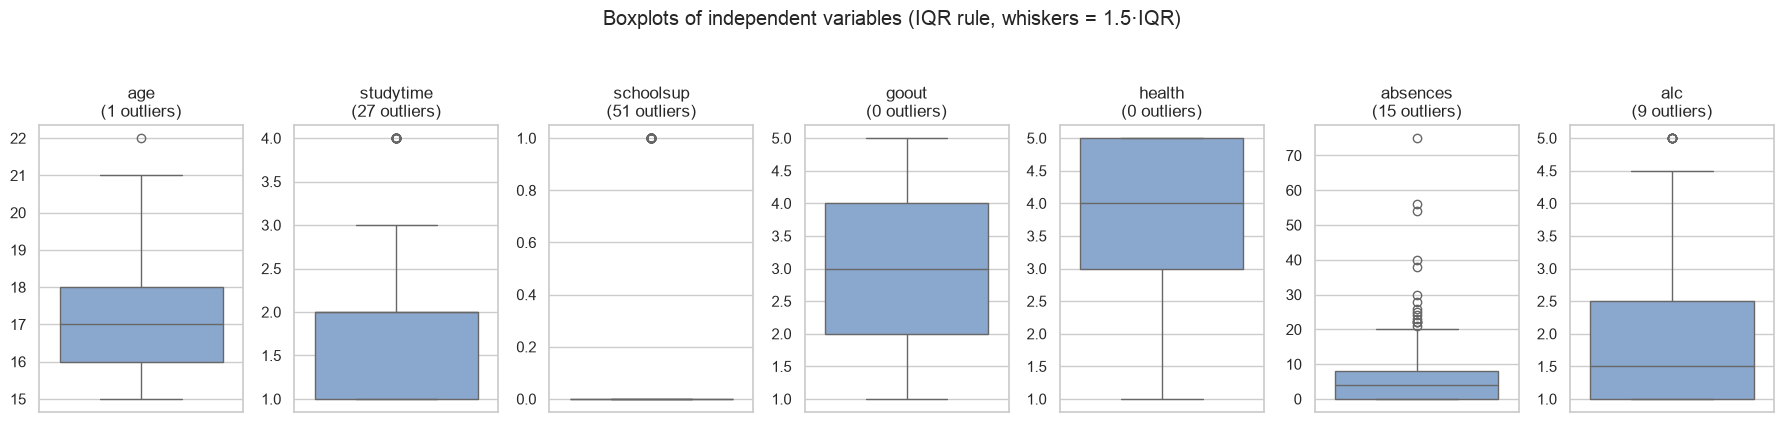

In [9]:
# Visualization for outlier detection: one boxplot per independent variable
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax, color="#7fa7d9")
    ax.set_title(f"{col}\n({outliers.set_index('feature').loc[col, 'n_outliers']} outliers)")
    ax.set_ylabel("")
plt.suptitle("Boxplots of independent variables (IQR rule, whiskers = 1.5·IQR)", y=1.05)
plt.tight_layout()
plt.show()

**Outlier counts (IQR rule):** age 1, studytime 27, schoolsup 51, goout 0, health 0, absences 15, alc 9.

- **schoolsup** is binary and 86.6% of students have 0, so $Q_1 = Q_3 = 0$ and IQR = 0. Every "yes" (51 students) is therefore flagged. These are not real outliers; the IQR method is not meaningful for a binary variable.
- **studytime** is an ordinal scale (1–4). Its IQR is 1, so the upper fence is 3.5 and every student in the top two categories is flagged. These are legitimate responses, not errors.
- **absences** is strongly right-skewed (median 4, max 75). Its 15 outliers (> 20 absences) are genuine high-absence students rather than data errors.
- **age** has one outlier (a 22-year-old), and **alc** has 9 (averages of 5, i.e., very heavy drinkers).

Since the flagged values are plausible, they are kept for modeling.

### iv. Standardize and run PCA

In [10]:
X = df[features]
y = df["G3"]

# Standardize the independent variables (mean 0, std 1).
# The target G3 is kept in its original units so MAE/RMSE are in grade points.
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)
X_std.describe().loc[["mean", "std"]].round(4)

,age,studytime,schoolsup,goout,health,absences,alc
mean,0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000,-0.0000
std,1.0013,1.0013,1.0013,1.0013,1.0013,1.0013,1.0013


In [11]:
# PCA on the standardized features
pca = PCA()
pcs = pca.fit_transform(X_std)

evr = pd.DataFrame({
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative": np.cumsum(pca.explained_variance_ratio_)
}, index=[f"PC{i+1}" for i in range(len(features))])
evr

,explained_variance_ratio,cumulative
PC1,0.2368,0.2368
PC2,0.1714,0.4081
PC3,0.1520,0.5601
PC4,0.1404,0.7005
PC5,0.1267,0.8272
PC6,0.0948,0.9220
PC7,0.0780,1.0000


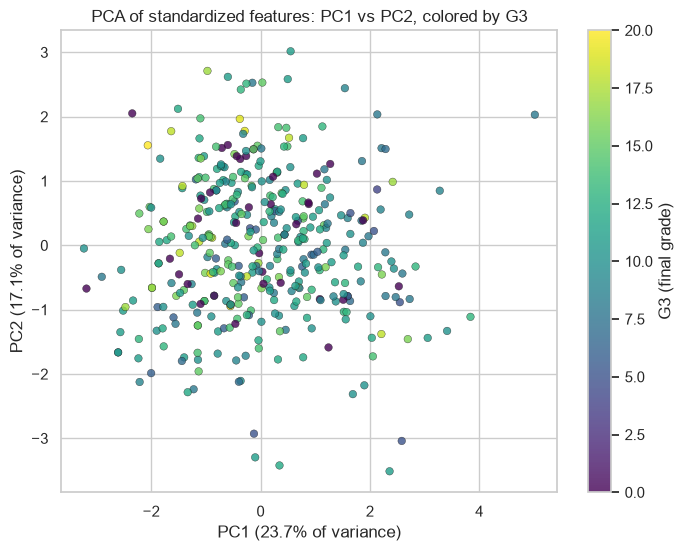

In [12]:
# Scatterplot of PC1 vs PC2, colored by final grade G3
plt.figure(figsize=(8, 6))
sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=y, cmap="viridis", s=30, alpha=0.8, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, label="G3 (final grade)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("PCA of standardized features: PC1 vs PC2, colored by G3")
plt.show()

In [13]:
# Component loadings for PC1 and PC2
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"])
loadings["|PC1|"] = loadings["PC1"].abs()
loadings["|PC2|"] = loadings["PC2"].abs()
loadings.sort_values("|PC1|", ascending=False)

,PC1,PC2,|PC1|,|PC2|
alc,0.5959,-0.2737,0.5959,0.2737
goout,0.4938,-0.1396,0.4938,0.1396
age,0.3819,0.5893,0.3819,0.5893
studytime,-0.3297,0.3857,0.3297,0.3857
absences,0.2801,0.1828,0.2801,0.1828
schoolsup,-0.2482,-0.4642,0.2482,0.4642
health,0.0805,-0.4009,0.0805,0.4009


In [14]:
# Top contributors to each component (by absolute loading)
for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().sort_values(ascending=False)
    print(f"{pc}: " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.3f})" for f in top.index[:3]))

PC1: alc (+0.596), goout (+0.494), age (+0.382)
PC2: age (+0.589), schoolsup (-0.464), health (-0.401)


**Explained variance:** PC1 explains 23.7% and PC2 17.1% of the variance (40.8% together). The variance is spread fairly evenly over all seven components, so no small number of components summarizes the data well.

**Loadings:**
- **PC1** is dominated by **alc (+0.60)** and **goout (+0.49)**, followed by age (+0.38) and studytime (−0.33). It can be read as a *social / drinking lifestyle* axis: students high on PC1 go out and drink more and study less.
- **PC2** is dominated by **age (+0.59)**, **schoolsup (−0.46)** and **health (−0.40)**, with studytime (+0.39). It roughly separates older students from younger students who receive extra school support.

**Scatterplot:** the colors (G3) are mixed throughout the PC1–PC2 plane with no visible gradient or clusters. Students with G3 = 0 (dark purple) appear everywhere. This already suggests that these seven features carry little information about the final grade.

## (b) Linear Regression
### i. Train/test split (80:20, seed 552)

In [15]:
# Use the standardized features from (a)iv
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (316, 7)  Test: (79, 7)


### ii. Build the three models (α = 0.1)

In [16]:
models = {
    "Linear": LinearRegression(),
    "Ridge (α=0.1)": Ridge(alpha=0.1),
    "Lasso (α=0.1)": Lasso(alpha=0.1),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name} fitted")

Linear fitted
Ridge (α=0.1) fitted
Lasso (α=0.1) fitted


### iii. Evaluate on the test set

In [17]:
results = {}
preds = {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    results[name] = {
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
        "Train R2": r2_score(y_train, m.predict(X_train)),
    }
metrics = pd.DataFrame(results).T
metrics

,MAE,RMSE,R2,Train R2
Linear,3.4180,4.7558,0.0282,0.0748
Ridge (α=0.1),3.4181,4.7559,0.0282,0.0748
Lasso (α=0.1),3.4471,4.7938,0.0126,0.0714


In [18]:
# Best model for each metric (lower MAE/RMSE is better, higher R2 is better)
best = {
    "MAE":  metrics["MAE"].idxmin(),
    "RMSE": metrics["RMSE"].idxmin(),
    "R2":   metrics["R2"].idxmax(),
}
for k, v in best.items():
    print(f"Best by {k}: {v}  ({metrics.loc[v, k]:.4f})")

Best by MAE: Linear  (3.4180)
Best by RMSE: Linear  (4.7558)
Best by R2: Linear  (0.0282)


| Metric | Best model |
|:--|:--|
| MAE (lower is better) | Linear (3.418) |
| RMSE (lower is better) | Linear (4.756) |
| R² (higher is better) | Linear (0.0282) |

Plain linear regression is best on all three metrics, but Ridge (α = 0.1) is practically identical: it differs only in the fourth decimal place. Lasso is slightly worse (MAE 3.447, RMSE 4.794, R² 0.013). All three models make errors of about 3.4–3.5 grade points on average on a 0–20 scale.

### Residual analysis

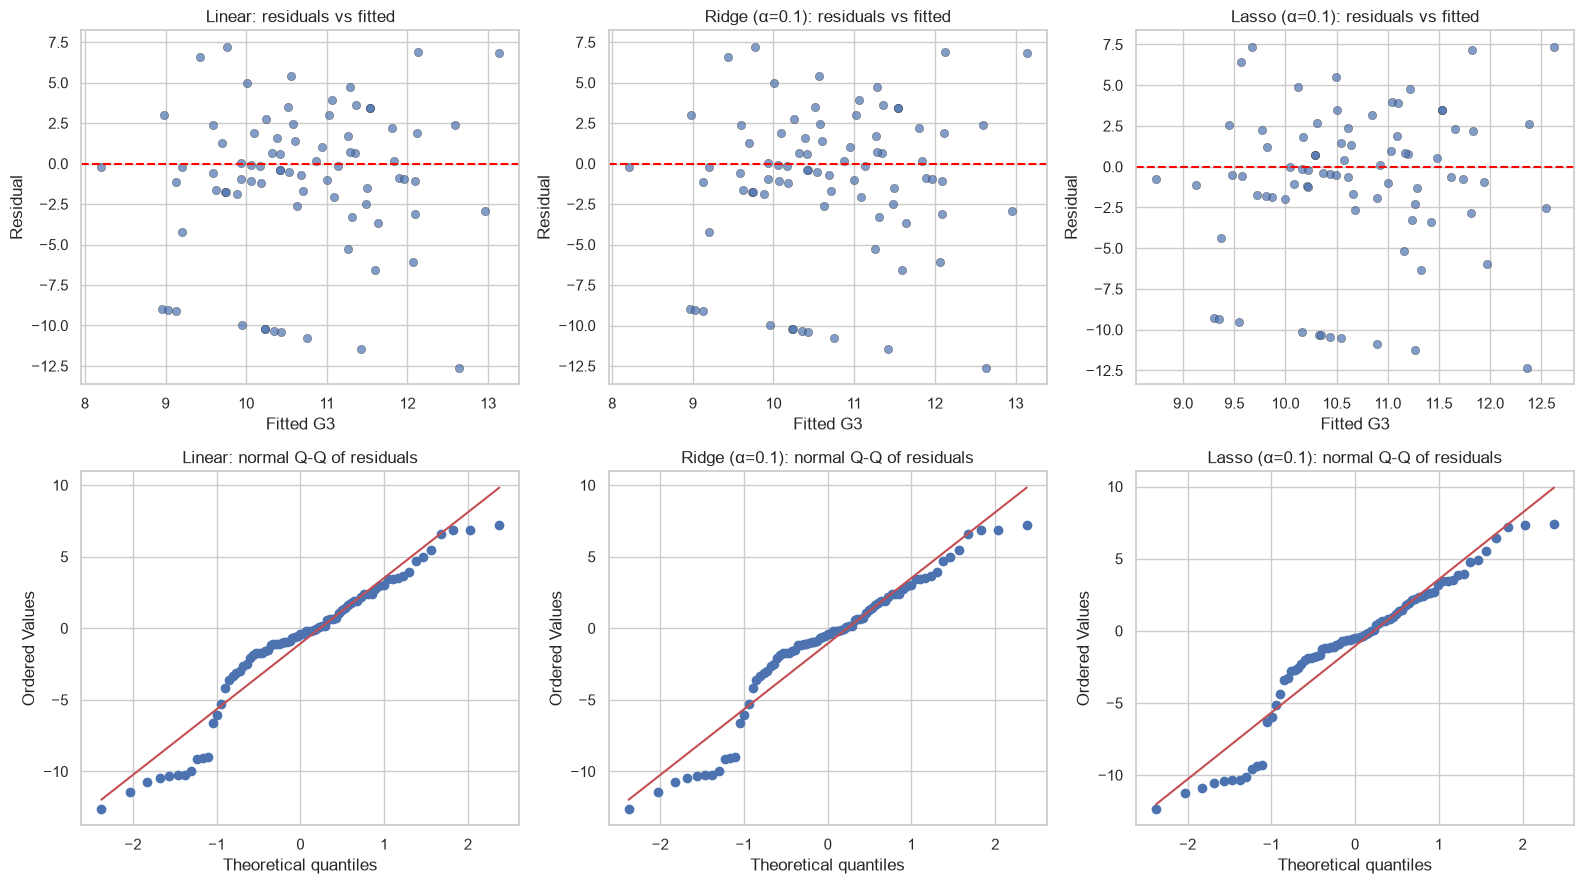

In [19]:
# Residual plots for each model: residuals vs fitted, and Q-Q plot
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, (name, p) in enumerate(preds.items()):
    resid = y_test - p
    ax = axes[0, j]
    ax.scatter(p, resid, alpha=0.7, edgecolor="k", linewidth=0.3)
    ax.axhline(0, color="red", ls="--")
    ax.set_title(f"{name}: residuals vs fitted")
    ax.set_xlabel("Fitted G3"); ax.set_ylabel("Residual")
    stats.probplot(resid, dist="norm", plot=axes[1, j])
    axes[1, j].set_title(f"{name}: normal Q-Q of residuals")
plt.tight_layout()
plt.show()

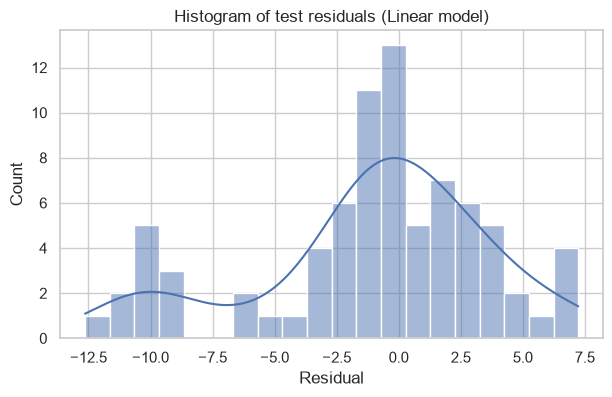

Students with G3 = 0 in full data: 38


In [20]:
# Distribution of test residuals (Linear model) and count of G3 = 0 cases
resid_lin = y_test - preds["Linear"]
plt.figure(figsize=(7, 4))
sns.histplot(resid_lin, bins=20, kde=True)
plt.title("Histogram of test residuals (Linear model)")
plt.xlabel("Residual"); plt.show()
print("Students with G3 = 0 in full data:", (y == 0).sum())

**Residual analysis:**
- The residuals vs fitted plots show a distinct band of large negative residuals (about −9 to −12.5). These are students with **G3 = 0** (38 in the full dataset), most likely students who dropped out or did not take the final exam. The model predicts around 9–12 for them, because none of the features identify them.
- Apart from that band, the residuals scatter around 0 without a clear funnel shape.
- The Q-Q plots confirm this: the residuals follow the normal line in the middle but the left tail drops well below it, so the residuals are left-skewed and not normal.
- The fitted values only range from about 8 to 13, while actual grades range from 0 to 20, which shows the models explain very little of the spread in G3.

### iv. Interpreting R²

All three models have a very low test R²: **0.028 (Linear), 0.028 (Ridge), 0.013 (Lasso)**. The models explain only about 1–3% of the variance in final grades on unseen data. Training R² is also low (about 0.07), so this is not mainly overfitting; the features themselves have little predictive power for G3.

The small gap between training R² (0.075) and test R² (0.028) shows some loss on new data, but the main problem is underfitting. The model is barely better than predicting the mean grade for everyone. Since previous grades (G1, G2) and failures are excluded, the strongest predictors of G3 are missing.

### v. Coefficients of the three models

In [21]:
coefs = pd.DataFrame({name: m.coef_ for name, m in models.items()}, index=features)
coefs.loc["(intercept)"] = [m.intercept_ for m in models.values()]
coefs

,Linear,Ridge (α=0.1),Lasso (α=0.1)
age,-0.7811,-0.7807,-0.6304
studytime,0.4448,0.4447,0.3491
schoolsup,-0.6825,-0.6822,-0.5475
goout,-0.5825,-0.5823,-0.4856
health,-0.2433,-0.2432,-0.1416
absences,0.1928,0.1927,0.0720
alc,0.0371,0.0369,-0.0000
(intercept),10.6294,10.6294,10.6251


### vi. Relationship between each independent variable and G3

Coefficients are on standardized features, so each value is the change in predicted G3 (grade points) for a one-standard-deviation increase in that feature, holding the others fixed. Signs are the same in all three models.

| Feature | Linear coef. | Relationship with G3 |
|:--|:--|:--|
| age | −0.78 | Negative, the strongest effect. Older students in this data tend to be those who repeated grades (age correlates 0.24 with past failures). |
| schoolsup | −0.68 | Negative. Students who receive extra school support score lower, probably because support is given to struggling students (not because it hurts). |
| goout | −0.58 | Negative. More time going out with friends is associated with lower grades. |
| studytime | +0.44 | Positive. More weekly study time is associated with higher grades. |
| health | −0.24 | Weakly negative, which is counterintuitive and likely noise. |
| absences | +0.19 | Weakly positive, which is counterintuitive. All 38 students with G3 = 0 have 0 recorded absences (they likely left school), which pulls this relationship upward. |
| alc | +0.04 | Essentially zero once goout and age are controlled for; Lasso sets it exactly to 0. |

The intercept (about 10.63) is the predicted G3 for a student with average values of every feature, since the features are standardized. These are associations, not causal effects, and all of them are small relative to the residual spread (RMSE ≈ 4.8).

### vii. How the regularization methods differ

**Ridge (L2)** adds $\alpha\sum\beta_j^2$. It shrinks all coefficients smoothly toward 0 but never makes them exactly 0. With α = 0.1 and 316 training points, the penalty is tiny compared with the squared-error term, so Ridge's coefficients are almost identical to OLS (e.g., age −0.7807 vs −0.7811).

**Lasso (L1)** adds $\alpha\sum|\beta_j|$. Its kink at 0 can set coefficients exactly to 0, so it also performs feature selection. At α = 0.1 it shrinks every coefficient noticeably (absences 0.19 → 0.07, health −0.24 → −0.14) and sets **alc** exactly to 0.

(In scikit-learn, Lasso's squared-error term is divided by $2n$ while Ridge's is not, so the same α is a much stronger penalty for Lasso. This explains why Lasso changes the coefficients far more at α = 0.1.)

**Conclusions about the data and features:**
- Regularization does not help here: OLS is already not overfitting (only 7 features, 316 samples), so shrinking the coefficients just adds bias and lowers R².
- The problem is a lack of signal, not variance. The features are only weakly related to G3 (all absolute correlations ≤ 0.16).
- Lasso dropping alc indicates that alcohol use adds no information beyond goout and age, with which it is correlated (r = 0.39 with goout; they load together on PC1).
- age, schoolsup, goout and studytime are the most robust predictors; they survive the longest as α increases.

### viii. Effect of increasing α
To support the answer, the models are refit over a range of α values.

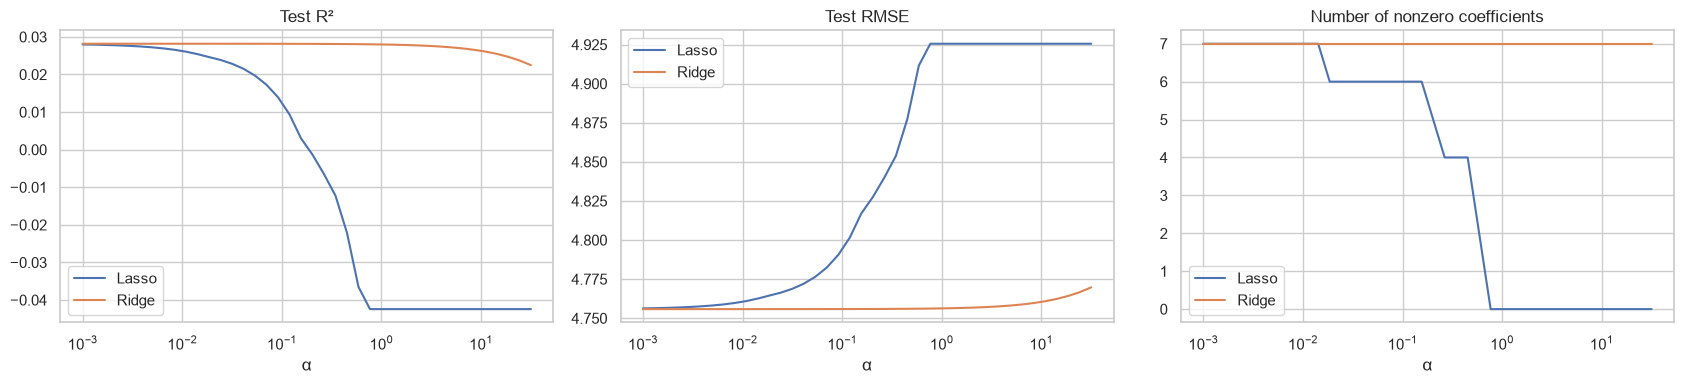

In [22]:
alphas = np.logspace(-3, 1.5, 40)
sweep = []
for a in alphas:
    for name, M in [("Ridge", Ridge), ("Lasso", Lasso)]:
        m = M(alpha=a, max_iter=10000).fit(X_train, y_train)
        p = m.predict(X_test)
        sweep.append([name, a, r2_score(y_test, p), np.sqrt(mean_squared_error(y_test, p)),
                      mean_absolute_error(y_test, p), int((np.abs(m.coef_) > 1e-10).sum())])
sweep = pd.DataFrame(sweep, columns=["model", "alpha", "R2", "RMSE", "MAE", "n_nonzero"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, g in sweep.groupby("model"):
    axes[0].plot(g.alpha, g.R2, label=name)
    axes[1].plot(g.alpha, g.RMSE, label=name)
    axes[2].plot(g.alpha, g.n_nonzero, label=name)
for ax, t in zip(axes, ["Test R²", "Test RMSE", "Number of nonzero coefficients"]):
    ax.set_xscale("log"); ax.set_xlabel("α"); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

In [23]:
# Lasso coefficients at a few α values
pd.DataFrame({f"α={a}": Lasso(alpha=a).fit(X_train, y_train).coef_ for a in [0.01, 0.1, 0.5, 1.0]},
             index=features)

,α=0.01,α=0.1,α=0.5,α=1.0
age,-0.7645,-0.6304,-0.1286,0.0
studytime,0.4315,0.3491,0.0000,0.0
schoolsup,-0.6694,-0.5475,-0.0469,0.0
goout,-0.5664,-0.4856,-0.1531,0.0
health,-0.2320,-0.1416,-0.0000,0.0
absences,0.1827,0.0720,0.0000,0.0
alc,0.0156,-0.0000,-0.0000,0.0


Increasing α makes performance **worse** on every metric for this dataset: MAE and RMSE increase and R² decreases.

- **Ridge:** the metrics change very slowly. Test R² stays near 0.028 up to α ≈ 1, falls to 0.026 at α = 10 and 0.013 at α = 100, and becomes negative at α = 1000. All 7 coefficients remain nonzero; they just shrink toward 0.
- **Lasso:** the metrics degrade much faster. Coefficients are removed one at a time (7 → 6 → 4 → 0 nonzero). By α ≈ 0.75 all coefficients are 0, the model predicts the training mean for everyone, and test R² becomes negative (≈ −0.04).

This happens because the unregularized model has low variance and high bias. Regularization trades variance for bias, so when there is little variance to remove, a larger α only adds bias (underfitting). In a problem with many correlated features or overfitting, a moderate α could instead improve test performance.

### ix. Feature engineering suggestions

1. **Handle G3 = 0 separately.** The 38 zero grades most likely represent dropouts, not low scores. Remove them or model them with a separate classifier ("did the student take the exam?") and then regress G3 on the rest.
2. **Add stronger predictors from the dataset:** `failures` (past class failures), `higher` (wants higher education), `Medu`/`Fedu` (parents' education). Including G1 and G2 would make R² very high, but should be done only if they are available at prediction time.
3. **Transform skewed variables:** use log(1 + absences) or bin absences to reduce the effect of the long right tail.
4. **Treat ordinal variables properly:** one-hot encode `studytime`, `goout` and `health` (or bin them) instead of treating 1–5 as equally spaced numbers, since their effects may be nonlinear.
5. **Interactions and polynomial terms:** e.g., `goout × alc`, `studytime × schoolsup`, `age²`, to capture nonlinear effects.
6. **Feature selection:** drop weak or redundant features (alc, health) based on Lasso or cross-validation.
7. **Avoid data leakage and tune properly:** fit the scaler on the training set only, and choose α by cross-validation (`RidgeCV` / `LassoCV`) instead of fixing it at 0.1.